# Detecção de Fraude em Cartão de Crédito

Classificação de transações fraudulentas em uma base pública muito desbalanceada, com avaliação pela classe de fraude e explicação das decisões com SHAP.

## Preparação do ambiente

In [16]:
%pip install seaborn scikit-learn xgboost shap

Note: you may need to restart the kernel to use updated packages.


In [17]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Estilo dos gráficos
sns.set_theme(style="whitegrid")

## Carga dos dados

Base pública de transações com cartão de crédito, lida diretamente por URL.

In [18]:
url = "https://storage.googleapis.com/download.tensorflow.org/data/creditcard.csv"
df = pd.read_csv(url)

print(f"Dataset carregado com {df.shape[0]} linhas e {df.shape[1]} colunas.")
df.head()

Dataset carregado com 284807 linhas e 31 colunas.


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


## Qualidade e desbalanceamento

Verificação de nulos e duplicatas e distribuição das classes.

In [19]:
print("Total de valores nulos no dataset:", df.isnull().sum().sum())
print("Total de linhas duplicadas:", df.duplicated().sum())

Total de valores nulos no dataset: 0
Total de linhas duplicadas: 1081


       Quantidade  Porcentagem (%)
Class                             
0          284315          99.8273
1             492           0.1727


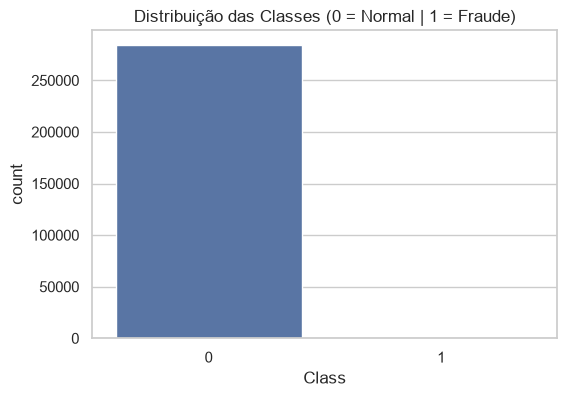

In [20]:
contagem = df['Class'].value_counts()
proporcao = df['Class'].value_counts(normalize=True) * 100

resumo_classes = pd.DataFrame({
    'Quantidade': contagem,
    'Porcentagem (%)': proporcao.round(4)
})
print(resumo_classes)

# Distribuição das classes
plt.figure(figsize=(6, 4))
sns.countplot(x='Class', data=df)
plt.title('Distribuição das Classes (0 = Normal | 1 = Fraude)')
plt.show()

In [21]:
print("--- Resumo estatístico: Transações Normais (Class = 0) ---")
print(df[df['Class'] == 0]['Amount'].describe().round(2))

print("\n--- Resumo estatístico: Fraudes (Class = 1) ---")
print(df[df['Class'] == 1]['Amount'].describe().round(2))

--- Resumo estatístico: Transações Normais (Class = 0) ---
count    284315.00
mean         88.29
std         250.11
min           0.00
25%           5.65
50%          22.00
75%          77.05
max       25691.16
Name: Amount, dtype: float64

--- Resumo estatístico: Fraudes (Class = 1) ---
count     492.00
mean      122.21
std       256.68
min         0.00
25%         1.00
50%         9.25
75%       105.89
max      2125.87
Name: Amount, dtype: float64


## Preparação dos dados

Remoção de duplicatas, transformação logarítmica de `Amount` e divisão estratificada em treino e teste. O scaler é ajustado só no treino.

In [22]:
# Remove duplicatas
df_limpo = df.drop_duplicates().copy()

# log1p suaviza a assimetria de Amount e está definida em 0
df_limpo['Amount_log'] = np.log1p(df_limpo['Amount'])

# Descarta o Amount original
df_limpo = df_limpo.drop(columns=['Amount'])

print(f"Shape após limpeza: {df_limpo.shape}")
print("Fraudes restantes após remover duplicadas:", df_limpo['Class'].sum())

Shape após limpeza: (283726, 31)
Fraudes restantes após remover duplicadas: 473


In [23]:
from sklearn.model_selection import train_test_split

X = df_limpo.drop(columns=['Class'])
y = df_limpo['Class']

# 80% treino, 20% teste, estratificado pela classe
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print(f"Treino: {X_train.shape[0]} amostras | Fraudes no treino: {y_train.sum()} ({y_train.mean()*100:.4f}%)")
print(f"Teste:  {X_test.shape[0]} amostras | Fraudes no teste:  {y_test.sum()} ({y_test.mean()*100:.4f}%)")

Treino: 226980 amostras | Fraudes no treino: 378 (0.1665%)
Teste:  56746 amostras | Fraudes no teste:  95 (0.1674%)


In [24]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

# O scaler é ajustado só no treino
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

## Modelos e métricas

A avaliação usa as métricas da classe de fraude e a PR-AUC. A acurácia não é usada, porque 99,83% das transações são legítimas.

In [25]:
from sklearn.metrics import classification_report, precision_score, recall_score, f1_score, average_precision_score

def avaliar_modelo(nome, y_true, y_pred, y_proba):
    print(f"=== {nome} ===")
    print(classification_report(y_true, y_pred, digits=4))

    # Métricas da classe de fraude (classe 1)
    prec = precision_score(y_true, y_pred)
    rec = recall_score(y_true, y_pred)
    f1 = f1_score(y_true, y_pred)
    pr_auc = average_precision_score(y_true, y_proba)

    return {
        'Modelo': nome,
        'Precisão (Fraude)': round(prec, 4),
        'Recall (Fraude)': round(rec, 4),
        'F1-Score (Fraude)': round(f1, 4),
        'PR-AUC': round(pr_auc, 4)
    }

resultados = []

In [ ]:
from sklearn.linear_model import LogisticRegression

lr = LogisticRegression(max_iter=1000, random_state=42)
lr.fit(X_train_scaled, y_train)

y_pred_lr = lr.predict(X_test_scaled)
y_proba_lr = lr.predict_proba(X_test_scaled)[:, 1]

resultados.append(avaliar_modelo("Regressão Logística (Baseline)", y_test, y_pred_lr, y_proba_lr))

### Random Forest

Configuração reduzida (30 árvores, profundidade máxima 8, 30% das amostras por árvore) para treinar mais rápido no Colab. A comparação com o XGBoost não tem o mesmo esforço de ajuste.

In [ ]:
from sklearn.ensemble import RandomForestClassifier

rf = RandomForestClassifier(
    n_estimators=30,
    max_depth=8,
    max_samples=0.3,         # 30% das amostras por árvore, para reduzir o tempo de treino
    class_weight='balanced',
    random_state=42,
    n_jobs=1
)
rf.fit(X_train_scaled, y_train)

y_pred_rf = rf.predict(X_test_scaled)
y_proba_rf = rf.predict_proba(X_test_scaled)[:, 1]

resultados.append(avaliar_modelo("Random Forest (Balanced)", y_test, y_pred_rf, y_proba_rf))

In [ ]:
from xgboost import XGBClassifier

# Razão de desbalanceamento no treino (normais / fraudes)
razao_desbalanceamento = (y_train == 0).sum() / (y_train == 1).sum()

xgb = XGBClassifier(
    n_estimators=100,
    scale_pos_weight=razao_desbalanceamento,
    tree_method='hist',  # Método mais rápido de construção das árvores
    random_state=42,
    eval_metric='logloss',
    n_jobs=2
)
xgb.fit(X_train_scaled, y_train)

y_pred_xgb = xgb.predict(X_test_scaled)
y_proba_xgb = xgb.predict_proba(X_test_scaled)[:, 1]

resultados.append(avaliar_modelo("XGBoost (Weighted)", y_test, y_pred_xgb, y_proba_xgb))

# Tabela comparativa
df_resultados = pd.DataFrame(resultados)
display(df_resultados)

## Curvas ROC e Precision-Recall

Comparação entre a regressão logística e o XGBoost. Com classes muito desbalanceadas, a curva ROC tende a parecer otimista, por isso a Precision-Recall é a referência.

In [ ]:
from sklearn.metrics import RocCurveDisplay, PrecisionRecallDisplay

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Curva ROC
RocCurveDisplay.from_predictions(y_test, y_proba_lr, name="Regressão Logística", ax=axes[0])
RocCurveDisplay.from_predictions(y_test, y_proba_xgb, name="XGBoost", ax=axes[0])
axes[0].set_title("Curva ROC (Visão Otimista)")
axes[0].plot([0, 1], [0, 1], "k--", label="Aleatório")

# Curva Precision-Recall
PrecisionRecallDisplay.from_predictions(y_test, y_proba_lr, name="Regressão Logística", ax=axes[1])
PrecisionRecallDisplay.from_predictions(y_test, y_proba_xgb, name="XGBoost", ax=axes[1])
axes[1].set_title("Curva Precision-Recall (Foco na Classe Fraude)")

plt.tight_layout()
plt.show()

## Ajuste de hiperparâmetros

`GridSearchCV` com o scaler dentro do `Pipeline`, otimizando recall.

In [ ]:
from sklearn.pipeline import Pipeline
from sklearn.model_selection import GridSearchCV

pipeline_xgb = Pipeline([
    ('scaler', StandardScaler()),
    ('clf', XGBClassifier(
        scale_pos_weight=razao_desbalanceamento,
        tree_method='hist',
        n_estimators=100,
        random_state=42,
        eval_metric='logloss',
        n_jobs=1
    ))
])

param_grid = {
    'clf__max_depth': [3, 5],
    'clf__learning_rate': [0.05, 0.1]
}

grid_search = GridSearchCV(
    estimator=pipeline_xgb,
    param_grid=param_grid,
    scoring='recall',
    cv=3,
    n_jobs=1
)

grid_search.fit(X_train, y_train)
print("Melhores hiperparâmetros encontrados:", grid_search.best_params_)
print(f"Melhor Recall na validação cruzada: {grid_search.best_score_:.4f}")

## Limiar de decisão

Comparação entre os limiares 0,5 e 0,3 no modelo ajustado.

In [ ]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

melhor_modelo = grid_search.best_estimator_
y_proba_best = melhor_modelo.predict_proba(X_test)[:, 1]

# Comparando limiar 0.5 vs 0.3
for limiar in [0.5, 0.3]:
    y_pred_limiar = (y_proba_best >= limiar).astype(int)
    print(f"\n--- Limiar de Decisão = {limiar} ---")
    print(f"Precisão: {precision_score(y_test, y_pred_limiar):.4f} | "
          f"Recall: {recall_score(y_test, y_pred_limiar):.4f} | "
          f"F1-Score: {f1_score(y_test, y_pred_limiar):.4f}")

# Matrizes de confusão para os limiares 0.5 e 0.3
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
ConfusionMatrixDisplay.from_predictions(y_test, (y_proba_best >= 0.5).astype(int), ax=axes[0], colorbar=False)
axes[0].set_title("Matriz de Confusão (Limiar 0.5)")

ConfusionMatrixDisplay.from_predictions(y_test, (y_proba_best >= 0.3).astype(int), ax=axes[1], colorbar=False)
axes[1].set_title("Matriz de Confusão (Limiar 0.3)")

plt.tight_layout()
plt.show()

## Explicabilidade (SHAP)

As variáveis `V1` a `V28` são anonimizadas: o SHAP indica quais componentes pesam na decisão, não o motivo de negócio. A visão global usa as 1.000 primeiras linhas do conjunto de teste.

In [ ]:
import shap

# Extrai scaler e XGBoost do Pipeline
scaler_final = melhor_modelo.named_steps['scaler']
xgb_final = melhor_modelo.named_steps['clf']

# Dados de teste escalados, com os nomes das colunas
X_test_df_scaled = pd.DataFrame(
    scaler_final.transform(X_test),
    columns=X_test.columns,
    index=X_test.index
)

# SHAP sobre as 1.000 primeiras linhas do teste (amostra, para reduzir o tempo)
explainer = shap.TreeExplainer(xgb_final)
X_amostra = X_test_df_scaled.iloc[:1000]
shap_values = explainer(X_amostra)

# Beeswarm: variáveis mais influentes e direção do impacto
plt.title("Impacto das Variáveis nas Previsões de Fraude (SHAP Summary)")
shap.plots.beeswarm(shap_values, max_display=10)

In [ ]:
# Primeira fraude do conjunto de teste
indice_fraude = y_test[y_test == 1].index[0]
linha_fraude = X_test_df_scaled.loc[[indice_fraude]]

# Calcular SHAP apenas para essa transação
shap_individual = explainer(linha_fraude)

print(f"Probabilidade prevista de fraude para esta transação: {melhor_modelo.predict_proba(X_test.loc[[indice_fraude]])[0][1]:.4f}")
shap.plots.waterfall(shap_individual[0], max_display=10)